# Hypothesis Testing

With the metrics and tracking implementation plan decided, we must perform a power analysis to derive the required sample size for our hypothesis testing. This can be calculated using our baseline OEC metrics and MDE of 2%. 

## Power Analysis

In [3]:
import math
import statsmodels.stats.power as power

# Assumed bassline OEC metrics and MDE
baseline_mean = 840.0  # Historic baseline minutes per user per week
baseline_std = 360.0  # Assumed behavioral standard deviation
mde_percent = 0.02  # 2% Minimum Detectable Effect

# Calculate the Absolute Detectable Effect and Effect Size (Cohen's d)
absolute_effect = baseline_mean * mde_percent
cohens_d = absolute_effect / baseline_std

print("--- Experiment Design Parameters ---")
print(f"Baseline Weekly Listening: {baseline_mean} minutes")
print(f"Target MDE Lift: {mde_percent * 100}% (+{absolute_effect:.2f} minutes)")
print(f"Calculated Effect Size (Cohen's d): {cohens_d:.4f}\n")

# Solve for sample size per variant (two-sided independent t-test)
analysis = power.TTestIndPower()
required_n_per_variant = analysis.solve_power(
    effect_size=cohens_d, 
    alpha=0.05, 
    power=0.80, 
    ratio=1.0, 
    alternative="two-sided"
)

print("--- Power Analysis Results ---")
print(f"Required sample size per variant: {math.ceil(required_n_per_variant)}")
print(f"Total users enrolled (1:1 Sample Ratio): {math.ceil(required_n_per_variant) * 2}")

--- Experiment Design Parameters ---
Baseline Weekly Listening: 840.0 minutes
Target MDE Lift: 2.0% (+16.80 minutes)
Calculated Effect Size (Cohen's d): 0.0467

--- Power Analysis Results ---
Required sample size per variant: 7210
Total users enrolled (1:1 Sample Ratio): 14420


## Dataset Validation

Next we'll load in the simulated dataset (generated via `data_simulation.py`) to check for Sample Ratio Mismatch (SRM). This will be done using a Chi-Square Goodness-of-Fit test. 

In [14]:
import pandas as pd
import scipy.stats as stats

# 1. Load the generated data file
df = pd.read_csv("data/simulated_experiment_log.csv")

# 2. Extract unique users per variant (Do not count daily rows, count unique people!)
observed_counts = df.groupby("variant")["user_id"].nunique().values
total_observed_users = observed_counts.sum()

# 3. Define our expected 50/50 split ratio
expected_counts = [total_observed_users / 2, total_observed_users / 2]

print("--- Sample Ratio Mismatch (SRM) Validation Check ---")
print(f"Total Unique Users Enrolled: {total_observed_users:,}")
print(f"Observed - Control: {observed_counts[0]:,} | Treatment: {observed_counts[1]:,}")
print(
    f"Expected - Control: {expected_counts[0]:,} | Treatment: {expected_counts[1]:,}\n"
)

# 4. Execute Chi-Square Goodness-of-Fit Test
chi2_stat, p_value = stats.chisquare(f_obs=observed_counts, f_exp=expected_counts)

print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"SRM Validation p-value: {p_value:.6f}")

# 5. Strategic Evaluation Rule
# In industry, an SRM check uses a super strict alpha of 0.001 to flag catastrophic pipeline bugs.
if p_value < 0.001:
    print(
        "🚨 CRITICAL WARNING: Sample Ratio Mismatch detected! The experiment assignment pipeline is corrupted."
    )
else:
    print(
        "✅ PASSED: No Sample Ratio Mismatch detected. Traffic allocation matches expectations."
    )

--- Sample Ratio Mismatch (SRM) Validation Check ---
Total Unique Users Enrolled: 14,420
Observed - Control: 7,135 | Treatment: 7,285
Expected - Control: 7,210.0 | Treatment: 7,210.0

Chi-Square Statistic: 1.5603
SRM Validation p-value: 0.211616
✅ PASSED: No Sample Ratio Mismatch detected. Traffic allocation matches expectations.


## Import via Mixpanel API
While the data generated from faker must be manually uploaded to BigQuery, we can utilize Mixpanel's API to import it directly. Run `data/mixpanel_import.py.`

## Results Analysis (pre-registered tests)

Everything here follows the frozen pre-registration: primary OEC via Welch's t-test (two-sided, α = 0.05), guardrails via the stated non-inferiority / halt rules, secondary metrics treated as diagnostic (Holm-corrected). Analysis unit is the **enrolled user**; churned users keep zeros for missing days.

In [5]:
import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests

# --- Pre-registered parameters (do not edit after seeing results) ---
ALPHA = 0.05
MDE_ABS = 16.8              # min/user/week (2% of 840)
RETENTION_MARGIN = 0.01     # roll back if W4 retention drops > 1pp (absolute) vs control
CRASH_HALT = 0.0005         # halt if crash rate rises > 0.05pp (absolute) vs control
rng = np.random.default_rng(7)

df = pd.read_csv("data/simulated_experiment_log.csv")

# One row per ENROLLED user
users = df.groupby(["user_id", "variant"], as_index=False).agg(
    is_complier=("is_complier", "max"),
    total=("total_minutes", "sum"),
    autoplay=("autoplay_minutes", "sum"),
    search_min=("search_minutes", "sum"),
    search_sessions=("search_sessions", "sum"),
    crashes=("crashes", "sum"),
    active_days=("experiment_day", "count"),
    w4=("w4_active_day", "max"),
)
for col in ["total", "autoplay", "search_min", "search_sessions"]:
    users[f"weekly_{col}"] = users[col] / 4.0  # 28 days -> average week

ctrl = users[users.variant == "control"]
trt = users[users.variant == "treatment"]
print(f"Control n={len(ctrl):,} | Treatment n={len(trt):,}")


def welch(t, c, alpha=ALPHA):
    """Welch two-sample test; returns diff (t - c), SE, CI, p, and approx. relative lift."""
    t, c = np.asarray(t, float), np.asarray(c, float)
    diff = t.mean() - c.mean()
    vt, vc = t.var(ddof=1) / len(t), c.var(ddof=1) / len(c)
    se = np.sqrt(vt + vc)
    dof = (vt + vc) ** 2 / (vt**2 / (len(t) - 1) + vc**2 / (len(c) - 1))
    p = 2 * stats.t.sf(abs(diff / se), dof)
    tcrit = stats.t.ppf(1 - alpha / 2, dof)
    lo, hi = diff - tcrit * se, diff + tcrit * se
    base = c.mean()  # relative CI ignores uncertainty in the baseline (approximation)
    return dict(diff=diff, se=se, lo=lo, hi=hi, p=p, rel=diff / base, rel_lo=lo / base, rel_hi=hi / base)

Control n=7,135 | Treatment n=7,285


### 1. Primary OEC: weekly streaming minutes per enrolled user (ITT)
Pre-registered test: two-sided Welch's t-test, reject H₀ if p < 0.05.

In [6]:
prim = welch(trt.weekly_total, ctrl.weekly_total)
print("PRIMARY OEC - weekly streaming minutes / enrolled user (Intent-to-Treat)")
print(f"  Control {ctrl.weekly_total.mean():.1f} | Treatment {trt.weekly_total.mean():.1f}")
print(f"  Lift: {prim['diff']:+.1f} min/wk ({prim['rel']:+.2%})")
print(f"  95% CI: [{prim['lo']:+.1f}, {prim['hi']:+.1f}] min/wk  ~  [{prim['rel_lo']:+.2%}, {prim['rel_hi']:+.2%}] relative (approx.)")
print(f"  Welch p = {prim['p']:.2e} -> {'REJECT H0' if prim['p'] < ALPHA else 'FAIL TO REJECT H0'} (alpha = {ALPHA})")
print(f"  MDE (design parameter, not a ship threshold) = +{MDE_ABS} min/wk | CI lower bound {'>=' if prim['lo'] >= MDE_ABS else '<'} MDE")

PRIMARY OEC - weekly streaming minutes / enrolled user (Intent-to-Treat)
  Control 834.5 | Treatment 861.2
  Lift: +26.6 min/wk (+3.19%)
  95% CI: [+14.7, +38.5] min/wk  ~  [+1.76%, +4.62%] relative (approx.)
  Welch p = 1.21e-05 -> REJECT H0 (alpha = 0.05)
  MDE (design parameter, not a ship threshold) = +16.8 min/wk | CI lower bound < MDE


### 2. Guardrails
**W4 retention** - non-inferiority: pass if the one-sided 95% lower bound of (treatment − control) stays above −1pp.
**Crash rate** - halt rule: fail if treatment exceeds control by more than +0.05pp. Rate is per user-day row (proxy for per-session); the pre-registered two-sample proportion z-test is applied at that grain.

In [7]:
# --- W4 retention (user-level binary) ---
n_t, n_c = len(trt), len(ctrl)
p_t, p_c = trt.w4.mean(), ctrl.w4.mean()
d_ret = p_t - p_c
se_ret = np.sqrt(p_t * (1 - p_t) / n_t + p_c * (1 - p_c) / n_c)
z_crit = stats.norm.ppf(1 - ALPHA)                      # one-sided 95%
lower_ret = d_ret - z_crit * se_ret
p_ni = stats.norm.sf((d_ret + RETENTION_MARGIN) / se_ret)  # H0: diff <= -margin
ret_pass = lower_ret > -RETENTION_MARGIN
print("GUARDRAIL - W4 retention")
print(f"  Control {p_c:.2%} | Treatment {p_t:.2%} | diff {d_ret*100:+.2f}pp")
print(f"  One-sided 95% lower bound: {lower_ret*100:+.2f}pp vs margin -{RETENTION_MARGIN*100:.1f}pp | non-inferiority p = {p_ni:.4f}")
print(f"  -> {'PASS' if ret_pass else 'FAIL (rollback)'}")

# --- Crash rate (per user-day row) ---
x_t, x_c = trt.crashes.sum(), ctrl.crashes.sum()
m_t, m_c = trt.active_days.sum(), ctrl.active_days.sum()
r_t, r_c = x_t / m_t, x_c / m_c
d_crash = r_t - r_c
se_crash = np.sqrt(r_t * (1 - r_t) / m_t + r_c * (1 - r_c) / m_c)
upper_crash = d_crash + z_crit * se_crash
crash_pass = d_crash <= CRASH_HALT
print("\nGUARDRAIL - crash rate per user-day")
print(f"  Control {r_c:.3%} | Treatment {r_t:.3%} | diff {d_crash*100:+.3f}pp")
print(f"  One-sided 95% upper bound: {upper_crash*100:+.3f}pp vs halt threshold +{CRASH_HALT*100:.2f}pp")
print(f"  -> {'PASS' if crash_pass else 'FAIL (emergency halt)'}"
      + ("" if upper_crash < CRASH_HALT else "  [note: upper bound crosses threshold - inconclusive, keep monitoring]"))

GUARDRAIL - W4 retention
  Control 95.21% | Treatment 94.95% | diff -0.26pp
  One-sided 95% lower bound: -0.85pp vs margin -1.0pp | non-inferiority p = 0.0197
  -> PASS

GUARDRAIL - crash rate per user-day
  Control 0.206% | Treatment 0.213% | diff +0.007pp
  One-sided 95% upper bound: +0.031pp vs halt threshold +0.05pp
  -> PASS


### 3. Secondary / cannibalization metrics
Diagnostic only (no ship/no-ship power). Holm correction across the three tests.

In [8]:
secondary = {
    "Autoplay minutes / wk": "weekly_autoplay",
    "Search minutes / wk": "weekly_search_min",
    "Search sessions / wk": "weekly_search_sessions",
}
rows = []
for label, col in secondary.items():
    r = welch(trt[col], ctrl[col])
    rows.append({"metric": label, "control": ctrl[col].mean(), "treatment": trt[col].mean(),
                 "diff": r["diff"], "ci_lo": r["lo"], "ci_hi": r["hi"], "p_raw": r["p"]})
sec = pd.DataFrame(rows)
sec["p_holm"] = multipletests(sec.p_raw, method="holm")[1]
sec["rel_%"] = sec["diff"] / sec["control"] * 100
print(sec.round({"control": 2, "treatment": 2, "diff": 2, "ci_lo": 2, "ci_hi": 2, "rel_%": 2}).to_string(index=False, float_format=lambda v: f"{v:.4g}"))

               metric  control  treatment  diff  ci_lo  ci_hi   p_raw  p_holm  rel_%
Autoplay minutes / wk      626      617.5 -8.43 -17.25   0.39 0.06101   0.183  -1.35
  Search minutes / wk    208.6      209.1  0.47   -2.5   3.44  0.7555       1   0.23
 Search sessions / wk    16.68       16.7  0.02  -0.23   0.27  0.8647       1   0.13


### 4. Adoption and CACE (Wald estimator)
ITT mixes adopters and non-adopters. Dividing by the adoption (compliance) rate gives the effect for users who actually use the banner. Valid under: random assignment, exclusion restriction (access without use has no effect), one-sided noncompliance (control has no access), and SUTVA (why messaging was dropped as the tested feature). CI via user-level bootstrap.

In [9]:
compliance = trt.is_complier.mean()           # Smart Queue Interaction Rate (diagnostic)
itt = trt.weekly_total.mean() - ctrl.weekly_total.mean()
cace = itt / compliance

ty, td, cy = trt.weekly_total.values, trt.is_complier.values, ctrl.weekly_total.values
B = 2000
boot = np.empty(B)
for b in range(B):
    ti = rng.integers(0, len(ty), len(ty))
    ci = rng.integers(0, len(cy), len(cy))
    boot[b] = (ty[ti].mean() - cy[ci].mean()) / td[ti].mean()
cace_lo, cace_hi = np.percentile(boot, [2.5, 97.5])

print(f"Adoption (Smart Queue Interaction Rate): {compliance:.2%} of treatment users")
print(f"ITT: {itt:+.1f} min/wk")
print(f"CACE = ITT / adoption = {cace:+.1f} min/wk (95% bootstrap CI [{cace_lo:+.1f}, {cace_hi:+.1f}])")
print(f"  i.e. {cace / ctrl.weekly_total.mean():+.1%} for users who actually use the banner")

Adoption (Smart Queue Interaction Rate): 40.00% of treatment users
ITT: +26.6 min/wk
CACE = ITT / adoption = +66.5 min/wk (95% bootstrap CI [+36.9, +97.2])
  i.e. +8.0% for users who actually use the banner


### 5. Novelty effect: does the lift decay?
Per-user weekly totals (zeros for churned users). Decay test compares each user's (week 1 − week 4) change across arms. The weeks 3-4 average is the better estimate of steady-state impact for the launch decision.

In [10]:
df["week"] = (df.experiment_day - 1) // 7 + 1
wk = (df.pivot_table(index="user_id", columns="week", values="total_minutes", aggfunc="sum", fill_value=0)
        .reindex(users.user_id, fill_value=0))
v = users.set_index("user_id").variant
is_t, is_c = (v == "treatment"), (v == "control")

weekly_rows = []
for w in [1, 2, 3, 4]:
    r = welch(wk.loc[is_t, w], wk.loc[is_c, w])
    weekly_rows.append({"week": w, "lift": r["diff"], "ci_lo": r["lo"], "ci_hi": r["hi"], "p": r["p"],
                        "rel_%": r["rel"] * 100})
weekly = pd.DataFrame(weekly_rows)
print(weekly.round(3).to_string(index=False))

late = wk[[3, 4]].mean(axis=1)
late_r = welch(late[is_t], late[is_c])
print(f"\nSteady-state lift (weeks 3-4 avg): {late_r['diff']:+.1f} min/wk ({late_r['rel']:+.2%}), "
      f"95% CI [{late_r['lo']:+.1f}, {late_r['hi']:+.1f}], p = {late_r['p']:.2e}")

decay = wk[1] - wk[4]
decay_r = welch(decay[is_t], decay[is_c])
print(f"Decay test (week1 - week4 per user, treatment vs control): {decay_r['diff']:+.1f} min/wk, "
      f"95% CI [{decay_r['lo']:+.1f}, {decay_r['hi']:+.1f}], p = {decay_r['p']:.3g}")

 week   lift  ci_lo  ci_hi     p  rel_%
    1 31.483 18.858 44.108 0.000  3.708
    2 30.303 17.889 42.718 0.000  3.591
    3 25.650 13.217 38.084 0.000  3.057
    4 19.040  5.360 32.721 0.006  2.361

Steady-state lift (weeks 3-4 avg): +22.3 min/wk (+2.72%), 95% CI [+9.9, +34.7], p = 4.13e-04
Decay test (week1 - week4 per user, treatment vs control): +12.4 min/wk, 95% CI [+3.4, +21.5], p = 0.00704


### 6. Figures for the memo

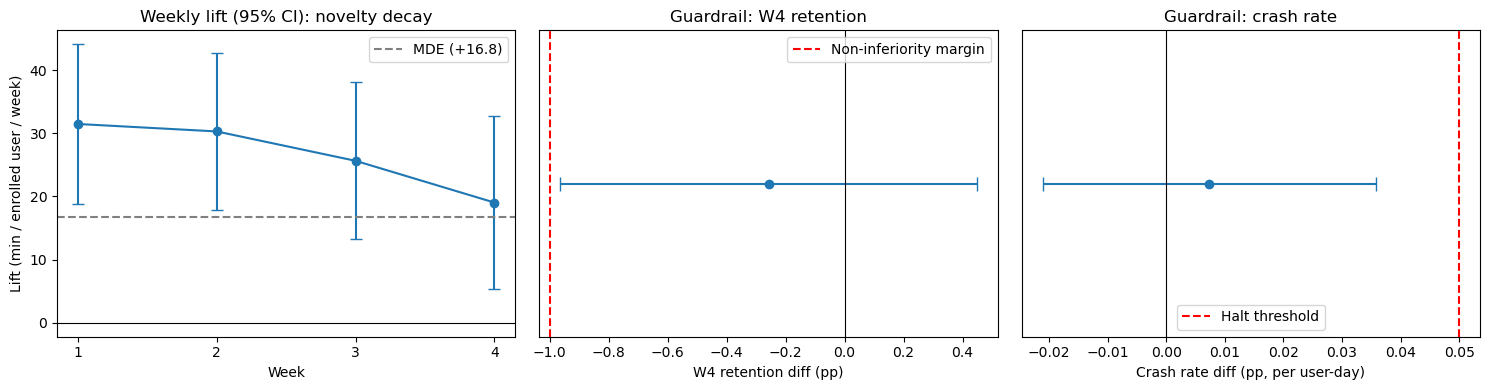

In [11]:
os.makedirs("figures", exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# (a) weekly lift with CI
ax = axes[0]
ax.errorbar(weekly.week, weekly.lift, yerr=[weekly.lift - weekly.ci_lo, weekly.ci_hi - weekly.lift],
            fmt="o-", capsize=4)
ax.axhline(MDE_ABS, ls="--", color="gray", label=f"MDE (+{MDE_ABS})")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks([1, 2, 3, 4]); ax.set_xlabel("Week"); ax.set_ylabel("Lift (min / enrolled user / week)")
ax.set_title("Weekly lift (95% CI): novelty decay"); ax.legend()

# (b) retention non-inferiority
ax = axes[1]
ci_lo_r = d_ret - stats.norm.ppf(0.975) * se_ret
ci_hi_r = d_ret + stats.norm.ppf(0.975) * se_ret
ax.errorbar([d_ret * 100], [0], xerr=[[(d_ret - ci_lo_r) * 100], [(ci_hi_r - d_ret) * 100]], fmt="o", capsize=5)
ax.axvline(-RETENTION_MARGIN * 100, ls="--", color="red", label="Non-inferiority margin")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks([]); ax.set_xlabel("W4 retention diff (pp)"); ax.set_title("Guardrail: W4 retention"); ax.legend()

# (c) crash rate halt rule
ax = axes[2]
ci_lo_c = d_crash - stats.norm.ppf(0.975) * se_crash
ci_hi_c = d_crash + stats.norm.ppf(0.975) * se_crash
ax.errorbar([d_crash * 100], [0], xerr=[[(d_crash - ci_lo_c) * 100], [(ci_hi_c - d_crash) * 100]], fmt="o", capsize=5)
ax.axvline(CRASH_HALT * 100, ls="--", color="red", label="Halt threshold")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks([]); ax.set_xlabel("Crash rate diff (pp, per user-day)"); ax.set_title("Guardrail: crash rate"); ax.legend()

plt.tight_layout()
plt.savefig("figures/results_summary.png", dpi=160, bbox_inches="tight")
plt.show()

### 7. Pre-registered decision rule

In [12]:
primary_sig = (prim["p"] < ALPHA) and (prim["diff"] > 0)
guardrails_ok = ret_pass and crash_pass

summary = pd.DataFrame([
    ["Primary OEC lift (ITT)", f"{prim['diff']:+.1f} min/wk ({prim['rel']:+.1%})", f"[{prim['lo']:+.1f}, {prim['hi']:+.1f}]", f"p = {prim['p']:.1e}", "SIG" if primary_sig else "NS"],
    ["Steady-state lift (wks 3-4)", f"{late_r['diff']:+.1f} min/wk ({late_r['rel']:+.1%})", f"[{late_r['lo']:+.1f}, {late_r['hi']:+.1f}]", f"p = {late_r['p']:.1e}", "context"],
    ["CACE (adopters only)", f"{cace:+.1f} min/wk", f"[{cace_lo:+.1f}, {cace_hi:+.1f}]", "bootstrap", "context"],
    ["W4 retention diff", f"{d_ret*100:+.2f}pp", f"lower bound {lower_ret*100:+.2f}pp", f"margin -{RETENTION_MARGIN*100:.0f}pp", "PASS" if ret_pass else "FAIL"],
    ["Crash rate diff", f"{d_crash*100:+.3f}pp", f"upper bound {upper_crash*100:+.3f}pp", f"halt +{CRASH_HALT*100:.2f}pp", "PASS" if crash_pass else "FAIL"],
], columns=["Metric", "Estimate", "95% interval / bound", "Rule", "Status"])
print(summary.to_string(index=False))

decision = "LAUNCH to 100%" if (primary_sig and guardrails_ok) else ("DO NOT LAUNCH - guardrail breach" if primary_sig else "DO NOT LAUNCH - primary not significant")
print(f"\nPre-registered decision: {decision}")
print(f"Planning note: expect roughly the weeks 3-4 lift ({late_r['rel']:+.1%}) at steady state, not the {weekly.loc[0, 'rel_%']:+.1f}% week-1 peak.")

                     Metric             Estimate 95% interval / bound         Rule  Status
     Primary OEC lift (ITT) +26.6 min/wk (+3.2%)       [+14.7, +38.5]  p = 1.2e-05     SIG
Steady-state lift (wks 3-4) +22.3 min/wk (+2.7%)        [+9.9, +34.7]  p = 4.1e-04 context
       CACE (adopters only)         +66.5 min/wk       [+36.9, +97.2]    bootstrap context
          W4 retention diff              -0.26pp  lower bound -0.85pp  margin -1pp    PASS
            Crash rate diff             +0.007pp upper bound +0.031pp halt +0.05pp    PASS

Pre-registered decision: LAUNCH to 100%
Planning note: expect roughly the weeks 3-4 lift (+2.7%) at steady state, not the +3.7% week-1 peak.
